In [20]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
import os
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import accuracy_score
from sklearn.feature_extraction.text import TfidfVectorizer
import matplotlib.pyplot as plt

In [4]:
#Posting path
posting_path = "datasets/posting"

In [5]:
dataset = pd.read_csv(os.path.join(posting_path, "fake_job_postings.csv"))

In [13]:
# Check for missing values

missing = dataset.isnull().sum()
missing_df = pd.DataFrame(missing, columns=["missing_count"])
missing_df["missing_percentage"] = (missing_df["missing_count"] / len(dataset)) * 100
missing_df = missing_df.sort_values(by="missing_percentage", ascending=False)
missing_df = missing_df[missing_df["missing_percentage"] > 0]
print(missing_df)

                     missing_count  missing_percentage
salary_range                 15012           83.959732
department                   11547           64.580537
required_education            8105           45.329978
benefits                      7212           40.335570
required_experience           7050           39.429530
function                      6455           36.101790
industry                      4903           27.421700
employment_type               3471           19.412752
company_profile               3308           18.501119
requirements                  2696           15.078300
location                       346            1.935123
description                      1            0.005593


In [18]:
# Check duplicate entries

duplicate_count = dataset.duplicated().sum()
print(f"Number of duplicate entries: {duplicate_count}")

dataset.describe()

Number of duplicate entries: 0


,job_id,telecommuting,has_company_logo,has_questions,fraudulent
count,17880.000000,17880.000000,17880.000000,17880.000000,17880.000000
mean,8940.500000,0.042897,0.795302,0.491723,0.048434
std,5161.655742,0.202631,0.403492,0.499945,0.214688
min,1.000000,0.000000,0.000000,0.000000,0.000000
25%,4470.750000,0.000000,1.000000,0.000000,0.000000
50%,8940.500000,0.000000,1.000000,0.000000,0.000000
75%,13410.250000,0.000000,1.000000,1.000000,0.000000
max,17880.000000,1.000000,1.000000,1.000000,1.000000


fraudulent
0    17014
1      866
Name: count, dtype: int64


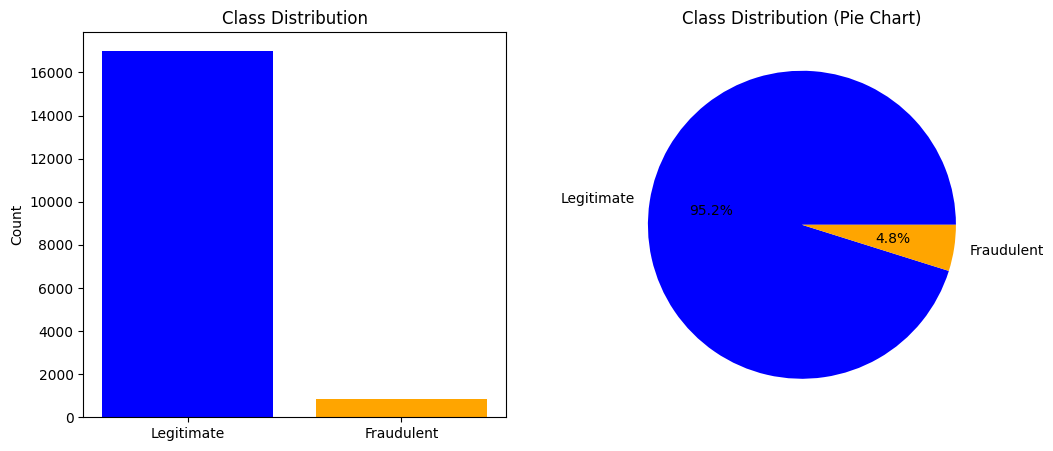

Imbalance Ratio (Legitimate:Fraudulent) = 19.65:1


In [25]:
target_counts = dataset["fraudulent"].value_counts()
print(target_counts)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].bar(["Legitimate", "Fraudulent"], target_counts.values, color=["blue", "orange"])
axes[0].set_title("Class Distribution")
axes[0].set_ylabel("Count")

axes[1].pie(target_counts.values, labels=["Legitimate", "Fraudulent"], autopct="%1.1f%%", colors=["blue", "orange"])
axes[1].set_title("Class Distribution (Pie Chart)")

plt.show()

imbalance_ratio = target_counts[0] / target_counts[1]
print(f"Imbalance Ratio (Legitimate:Fraudulent) = {imbalance_ratio:.2f}:1")